In [11]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
import kagglehub
import scipy.stats as stats
from scipy.stats import chi2_contingency

path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")
csv_path = os.path.join(path,"amz_uk_price_prediction_dataset.csv" )
df = pd.read_csv(csv_path)

df.head()


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [2]:
df.shape

(2443651, 9)

In [3]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [5]:
df.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*


2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.


In [15]:
crosstab = pd.crosstab(df["category"], df["isBestSeller"])
crosstab

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [16]:
crosstab["proportion_best_seller"] = crosstab[True] / (crosstab[False]+ crosstab[True])
crosstab_sorted = crosstab.sort_values(by="proportion_best_seller", ascending=False)
crosstab_sorted.head(10)

isBestSeller,False,True,proportion_best_seller
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339
"Billiard, Snooker & Pool",241,8,0.032129
Pet Supplies,9152,285,0.030200
Home Brewing & Wine Making,239,7,0.028455
Wind Instruments,243,7,0.028000


Conclusion:
The categories with the highest proportion of best-sellers are: Grocery, Smart Home Security & Lighting and Health & Personal Care

In [17]:
chi2, p, dof, expected = chi2_contingency(pd.crosstab(df ["category"], df["isBestSeller"]))
print("Chi-square statistic:", chi2)
print("p-value:",p)
print("Degrees of freedom:",dof)

Chi-square statistic: 36540.20270061387
p-value: 0.0
Degrees of freedom: 295


In [18]:
n = df.shape[0]
table = pd.crosstab(df["category"], df["isBestSeller"])
cramers_v = np.sqrt(chi2 / (n*(min(table.shape)-1)))
print("Cramer's V:", cramers_v)

Cramer's V: 0.1222829439760564


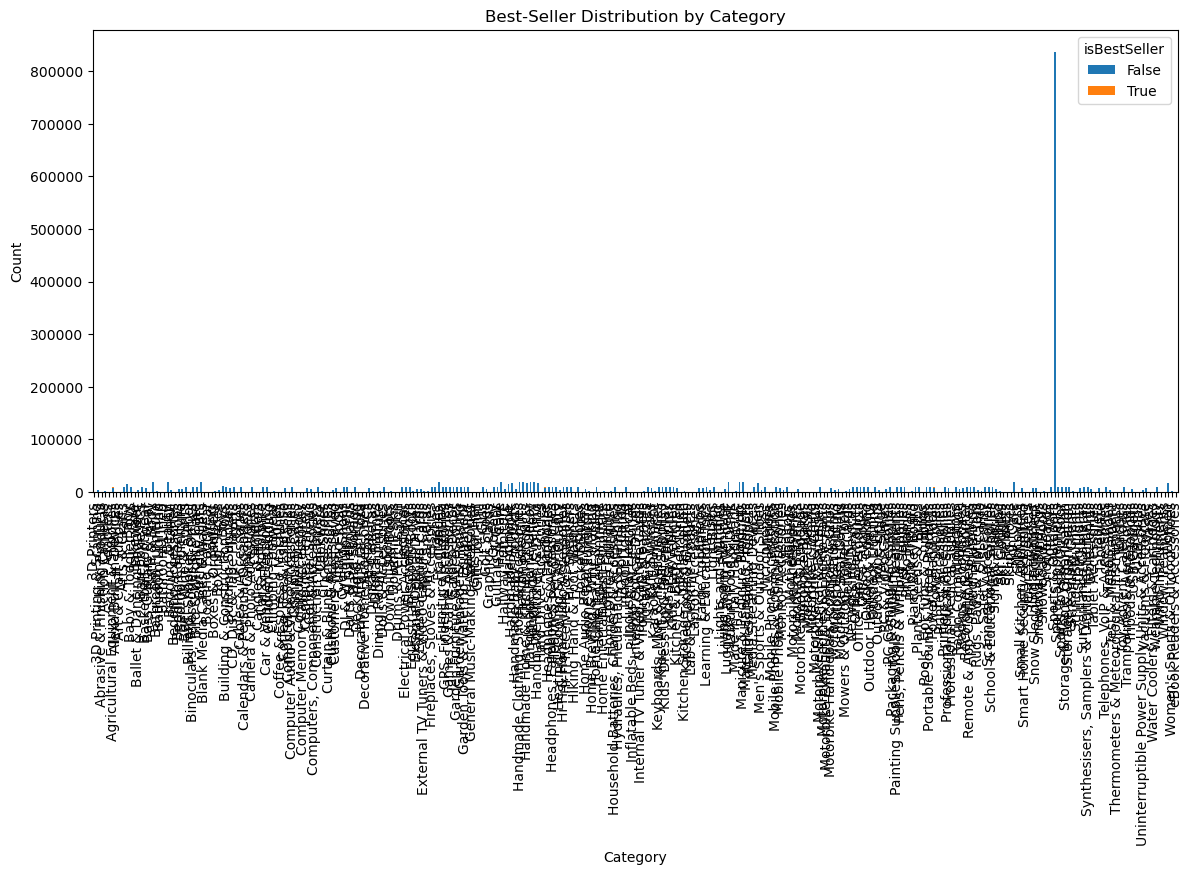

In [19]:
crosstab_plot = pd. crosstab(df["category"],df["isBestSeller"])
crosstab_plot.plot(kind="bar", stacked=True, figsize=(14,6))
plt.title("Best-Seller Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Count")
plt.show()

The stacked bar chart shows that some categories contain more best-sellers than others, but no best-sellers are still the majority

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [20]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

df_clean = df[(df["price"] >= lower_limit) & (df["price"] <= upper_limit)]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Original shape:", df.shape)
print("Clean shape:", df_clean.shape)

Q1: 9.99
Q3: 45.99
IQR: 36.0
Lower limit: -44.01
Upper limit: 99.99000000000001
Original shape: (2443651, 9)
Clean shape: (2115963, 9)


In [21]:
top20_categories = df_clean["category"].value_counts().nlargest(20).index
top20_df = df_clean[df_clean["category"].isin(top20_categories)]

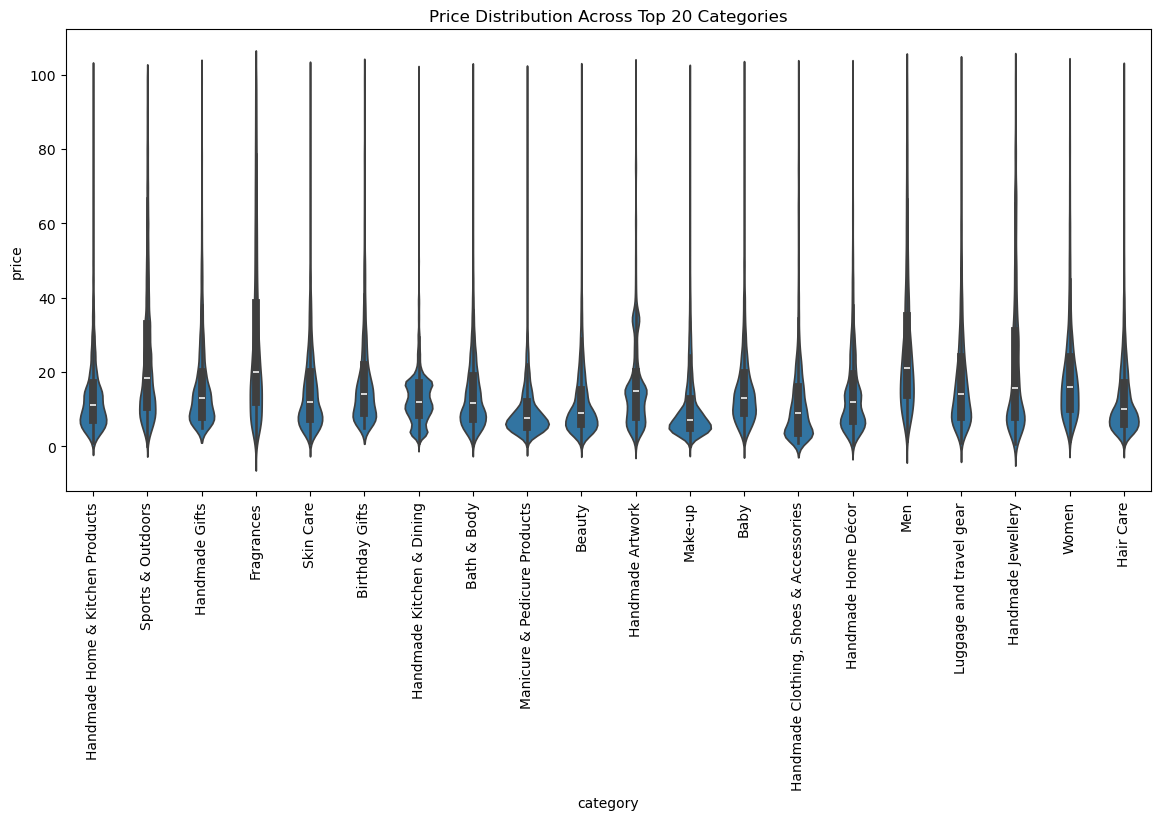

In [22]:
plt.figure(figsize=(14,6))
sns.violinplot(data=top20_df, x="category",y="price")
plt.xticks(rotation=90)
plt.title("Price Distribution Across Top 20 Categories")
plt.show()

In [23]:
median_price_by_category = df_clean.groupby("category")["price"].median().sort_values(ascending=False)
median_price_by_category.head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

In [24]:
top10_categories = df_clean["category"].value_counts().nlargest(10).index
top10_df = df_clean[df_clean["category"].isin(top10_categories)]

avg_price_top10 = top10_df.groupby("category")["price"].mean().sort_values(ascending=False)
avg_price_top10

category
Sports & Outdoors                         25.172065
Birthday Gifts                            18.600195
Handmade Gifts                            17.395112
Skin Care                                 15.654722
Bath & Body                               14.678683
Hair Care                                 13.461408
Handmade Clothing, Shoes & Accessories    12.958639
Beauty                                    12.523480
Make-up                                   10.612918
Manicure & Pedicure Products              10.231825
Name: price, dtype: float64

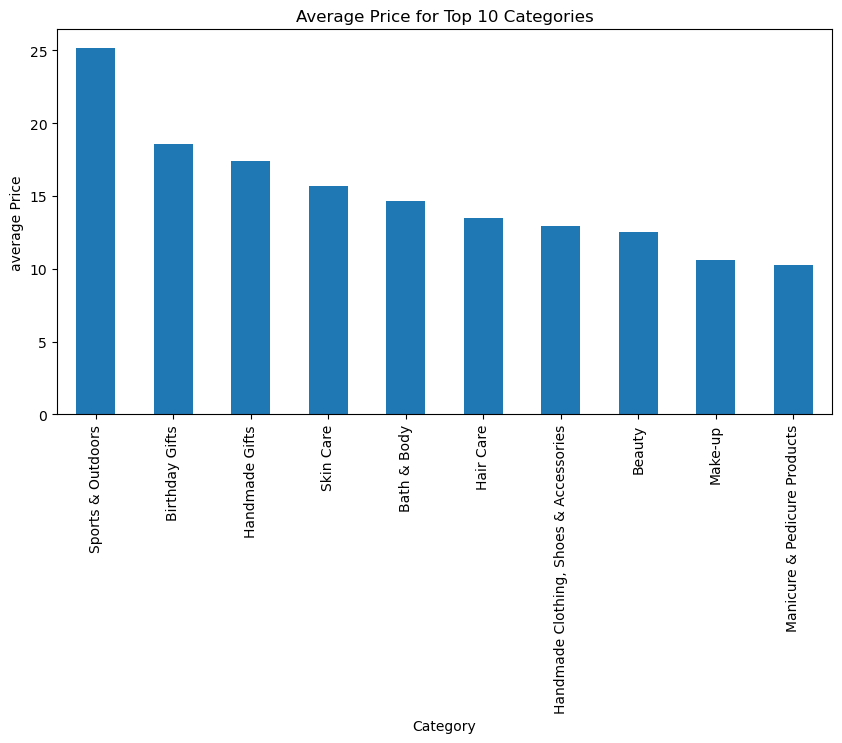

In [25]:
avg_price_top10.plot(kind="bar", figsize=(10,5))
plt.title("Average Price for Top 10 Categories")
plt.xlabel("Category")
plt.ylabel("average Price")
plt.show()

In [27]:
avg_price_all = df_clean.groupby("category")["price"].mean().sort_values(ascending=False)
avg_price_all.head(10)

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

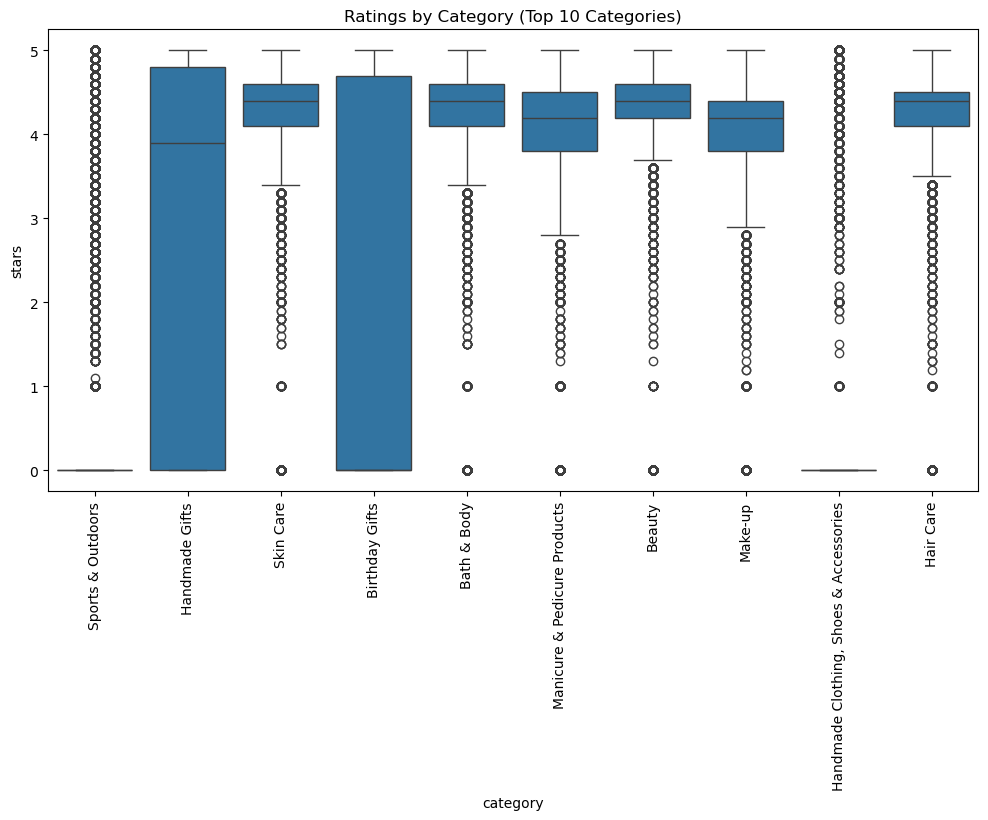

In [29]:
plt.figure(figsize=(12,6))
sns.boxplot(data=top10_df, x="category", y="stars")
plt.xticks(rotation=90)
plt.title("Ratings by Category (Top 10 Categories)")
plt.show()

In [30]:
median_rating_by_category = df_clean.groupby("category")["stars"].median().sort_values(ascending=False)
median_rating_by_category.head(10)

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Hobbies                         4.6
Beer, Wine & Spirits            4.6
Laptop Accessories              4.6
Cables & Accessories            4.5
CPUs                            4.5
Name: stars, dtype: float64

Conclusion:
- The category with the highest median rating overall is: Computer Memory with median rating of 4.7
- Among the top 10 most common categories, the highest median rating is: Bath & Body, Beauty, Hair care and Skin Care.  All of them have a median rating of 4.4



### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

In [31]:
correlation = df_clean ["price"].corr(df_clean["stars"])
print("Correlation between price and stars:", correlation)

Correlation between price and stars: -0.07767299878194293


There is a very weak negative correlation between price and rating

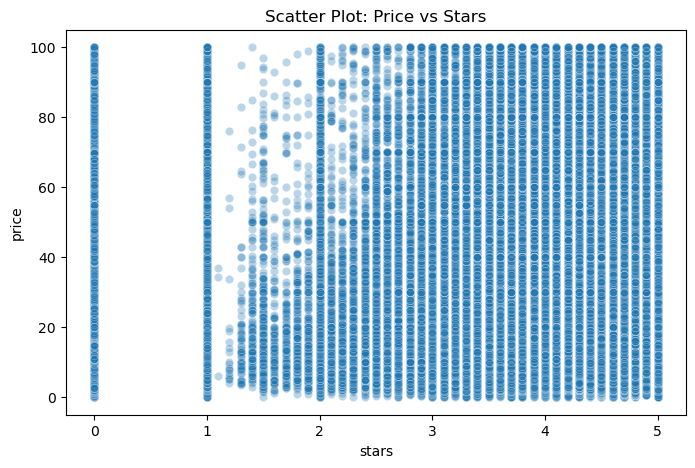

In [32]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df_clean, x="stars",y="price",alpha=0.3)
plt.title("Scatter Plot: Price vs Stars")
plt.show()

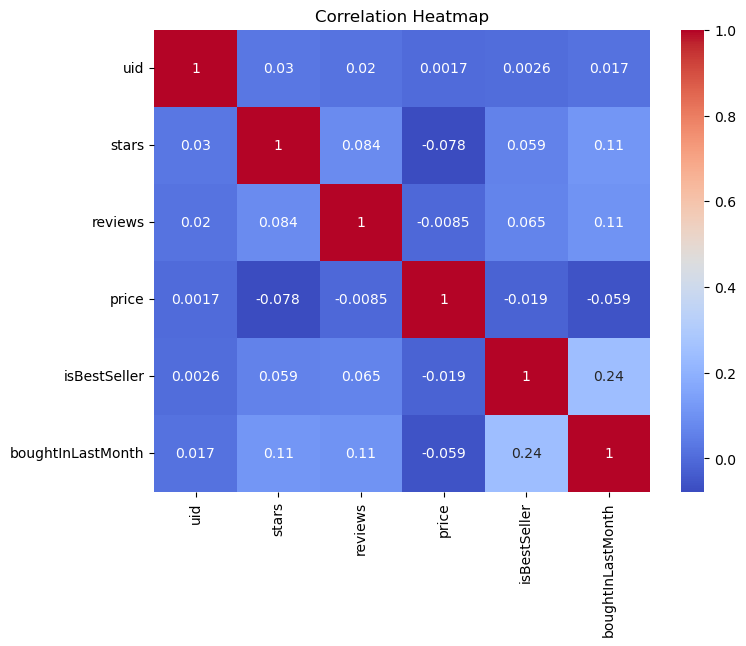

In [33]:
corr_matrix = df_clean[["uid","stars","reviews","price","isBestSeller","boughtInLastMonth"]].corr(numeric_only=True)
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

Correlations:
- price and stars: -0.078
-price and reviews: -0.008
- isBestSeller and boughtInLastMonth: 0.243
The strongest  relationship is between being a best-seller and products bought in the last month 

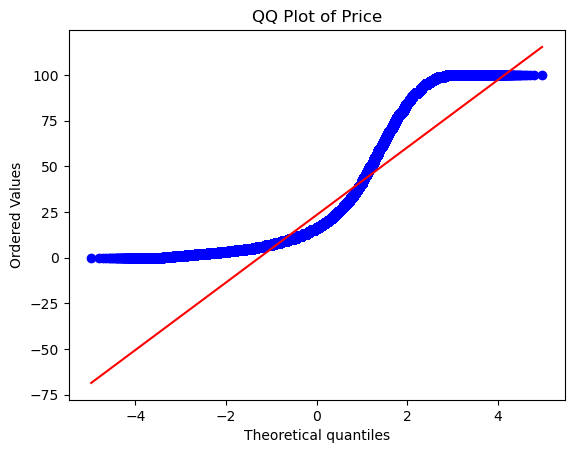

In [34]:
stats.probplot(df_clean["price"], dist="norm", plot=plt)
plt.title("QQ Plot of Price")
plt.show()

the price variable does not follow a normal distribution

Final business-centric report:
- Some categories such as Grocery, Smart Home Security & Lighting, and Health & Personal Care have a higher proportion of best-selling products.
- Price vary a lot depending on category. Sports & Outdoors has the highest average price
-The correlation between price and stars is very weak and negative.
- Product prices are not normally distributed 